# IEEE-CIS Fraud Detection — Exploration and Baseline Models

This notebook explores the IEEE-CIS transaction dataset, examines missingness and fraud patterns, creates a chronological train/validation/test split, and evaluates Logistic Regression baselines with progressively richer feature sets.

**Data requirement:** The notebook downloads the IEEE-CIS Fraud Detection competition files with `kagglehub`. You need a Kaggle account, access to the competition, and acceptance of its rules. The dataset is not included in this repository, and credentials must never be committed to GitHub.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Imports and Kaggle dataset setup


In [3]:
%pip install -q kagglehub


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os
import kagglehub

# Authenticate with your own Kaggle account when prompted.
kagglehub.login()

path = kagglehub.competition_download("ieee-fraud-detection")
print("Dataset directory:", path)
print("Available files:", os.listdir(path))

Dataset directory: C:\Users\HP\.cache\kagglehub\competitions\ieee-fraud-detection
Available files: ['sample_submission.csv', 'test_identity.csv', 'test_transaction.csv', 'train_identity.csv', 'train_transaction.csv']


In [5]:
train_transaction = pd.read_csv(
    os.path.join(path, "train_transaction.csv")
)

In [6]:
train_transaction.shape

(590540, 394)

In [7]:
train_transaction.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
train_transaction.columns.tolist()

['TransactionID',
 'isFraud',
 'TransactionDT',
 'TransactionAmt',
 'ProductCD',
 'card1',
 'card2',
 'card3',
 'card4',
 'card5',
 'card6',
 'addr1',
 'addr2',
 'dist1',
 'dist2',
 'P_emaildomain',
 'R_emaildomain',
 'C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'C6',
 'C7',
 'C8',
 'C9',
 'C10',
 'C11',
 'C12',
 'C13',
 'C14',
 'D1',
 'D2',
 'D3',
 'D4',
 'D5',
 'D6',
 'D7',
 'D8',
 'D9',
 'D10',
 'D11',
 'D12',
 'D13',
 'D14',
 'D15',
 'M1',
 'M2',
 'M3',
 'M4',
 'M5',
 'M6',
 'M7',
 'M8',
 'M9',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'V29',
 'V30',
 'V31',
 'V32',
 'V33',
 'V34',
 'V35',
 'V36',
 'V37',
 'V38',
 'V39',
 'V40',
 'V41',
 'V42',
 'V43',
 'V44',
 'V45',
 'V46',
 'V47',
 'V48',
 'V49',
 'V50',
 'V51',
 'V52',
 'V53',
 'V54',
 'V55',
 'V56',
 'V57',
 'V58',
 'V59',
 'V60',
 'V61',
 'V62',
 'V63',
 'V64',
 'V

In [9]:
train_transaction["isFraud"].value_counts()

isFraud
0    569877
1     20663
Name: count, dtype: int64

In [10]:
train_transaction["isFraud"].value_counts(normalize=True) * 100

isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

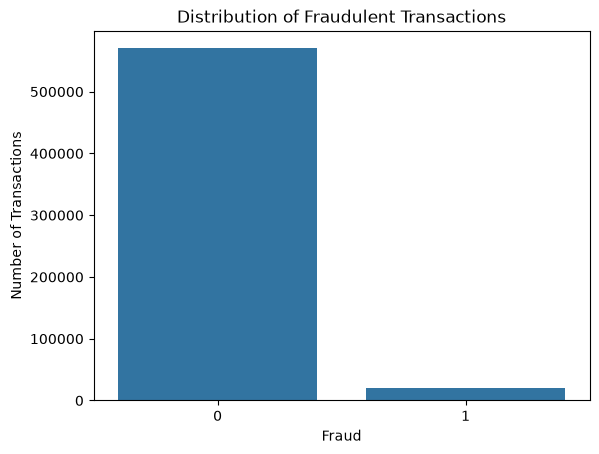

In [11]:
sns.countplot(data=train_transaction, x="isFraud")

plt.title("Distribution of Fraudulent Transactions")
plt.xlabel("Fraud")
plt.ylabel("Number of Transactions")
plt.show()

## 2. Transaction amount and product-level exploration


In [12]:
train_transaction.describe()

,TransactionID,isFraud,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
count,5.905400e+05,590540.000000,5.905400e+05,590540.000000,590540.000000,581607.000000,588975.000000,586281.000000,524834.000000,524834.000000,...,82351.000000,82351.000000,82351.000000,82351.000000,82351.000000,82351.00000,82351.000000,82351.000000,82351.000000,82351.000000
mean,3.282270e+06,0.034990,7.372311e+06,135.027176,9898.734658,362.555488,153.194925,199.278897,290.733794,86.800630,...,0.775874,721.741883,1375.783644,1014.622782,9.807015,59.16455,28.530903,55.352422,151.160542,100.700882
std,1.704744e+05,0.183755,4.617224e+06,239.162522,4901.170153,157.793246,11.336444,41.244453,101.741072,2.690623,...,4.727971,6217.223583,11169.275702,7955.735482,243.861391,387.62948,274.576920,668.486833,1095.034387,814.946722
min,2.987000e+06,0.000000,8.640000e+04,0.251000,1000.000000,100.000000,100.000000,100.000000,100.000000,10.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,3.134635e+06,0.000000,3.027058e+06,43.321000,6019.000000,214.000000,150.000000,166.000000,204.000000,87.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
50%,3.282270e+06,0.000000,7.306528e+06,68.769000,9678.000000,361.000000,150.000000,226.000000,299.000000,87.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
75%,3.429904e+06,0.000000,1.124662e+07,125.000000,14184.000000,512.000000,150.000000,226.000000,330.000000,87.000000,...,0.000000,0.000000,25.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
max,3.577539e+06,1.000000,1.581113e+07,31937.391000,18396.000000,600.000000,231.000000,237.000000,540.000000,102.000000,...,55.000000,160000.000000,160000.000000,160000.000000,55125.000000,55125.00000,55125.000000,104060.000000,104060.000000,104060.000000


In [13]:
train_transaction["TransactionAmt"].describe()

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64

In [14]:
train_transaction["TransactionAmt"].median()

np.float64(68.769)

In [15]:
train_transaction["TransactionAmt"].max()

np.float64(31937.391)

In [16]:
train_transaction.groupby("isFraud")["TransactionAmt"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,134.511665,239.395078,0.251,43.970,68.5,120.0,31937.391
1,20663.0,149.244779,232.212163,0.292,35.044,75.0,161.0,5191.000


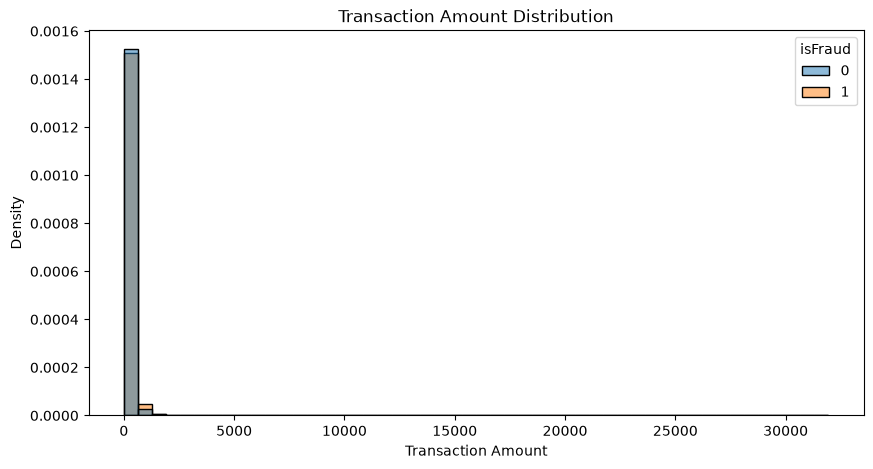

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_transaction,
    x="TransactionAmt",
    hue="isFraud",
    bins=50,
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.show()

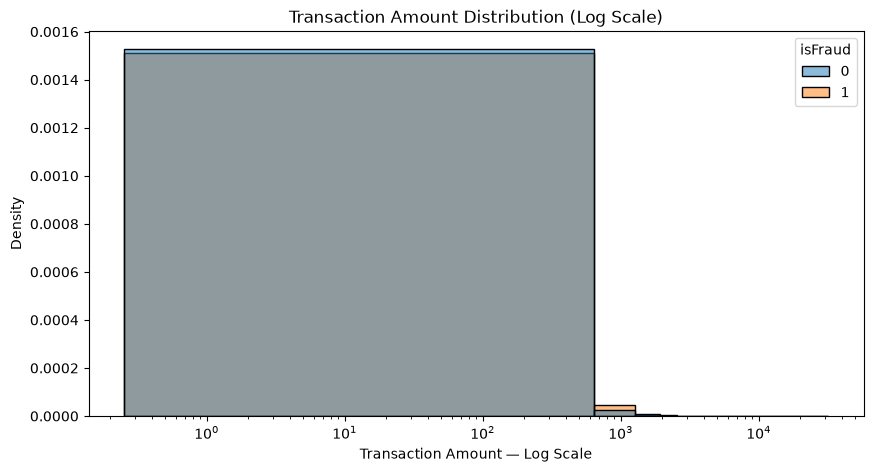

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_transaction,
    x="TransactionAmt",
    hue="isFraud",
    bins=50,
    stat="density",
    common_norm=False
)

plt.xscale("log")

plt.title("Transaction Amount Distribution (Log Scale)")
plt.xlabel("Transaction Amount — Log Scale")
plt.ylabel("Density")
plt.show()

In [19]:
train_transaction["ProductCD"].value_counts()

ProductCD
W    439670
C     68519
R     37699
H     33024
S     11628
Name: count, dtype: int64

In [20]:
fraud_by_product = (
    train_transaction.groupby("ProductCD")["isFraud"]
    .mean()
    .sort_values(ascending=False)
)

fraud_by_product

ProductCD
C    0.116873
S    0.058996
H    0.047662
R    0.037826
W    0.020399
Name: isFraud, dtype: float64

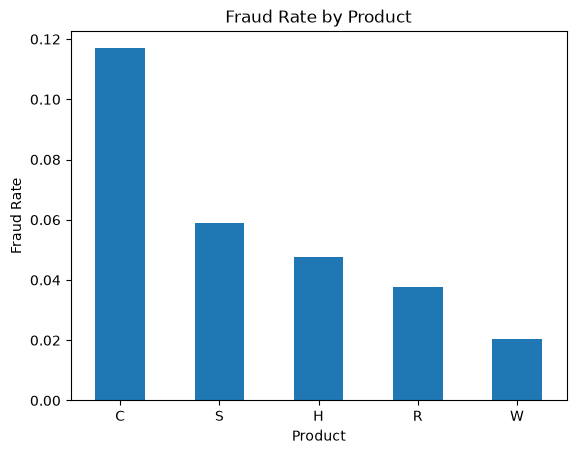

In [21]:
fraud_by_product.plot(kind="bar")

plt.title("Fraud Rate by Product")
plt.xlabel("Product")
plt.ylabel("Fraud Rate")
plt.xticks(rotation=0)
plt.show()

## 3. Missing values and feature families


In [22]:
missing = train_transaction.isnull().sum()

missing_percentage = (
    missing / len(train_transaction) * 100
).sort_values(ascending=False)

missing_percentage.head(20)

dist2    93.628374
D7       93.409930
D13      89.509263
D14      89.469469
D12      89.041047
D6       87.606767
D9       87.312290
D8       87.312290
V153     86.123717
V149     86.123717
V141     86.123717
V146     86.123717
V154     86.123717
V162     86.123717
V142     86.123717
V158     86.123717
V161     86.123717
V157     86.123717
V138     86.123717
V139     86.123717
dtype: float64

In [23]:
d7_missing_fraud = (
    train_transaction.groupby(
        train_transaction["D7"].isna()
    )["isFraud"]
    .mean()
    .rename(index={
        False: "D7 present",
        True: "D7 missing"
    })
)

d7_missing_fraud

D7
D7 present    0.148778
D7 missing    0.026962
Name: isFraud, dtype: float64

In [24]:
train_transaction["D7"].isna().value_counts()

D7
True     551623
False     38917
Name: count, dtype: int64

In [25]:
from collections import Counter

prefixes = []

for col in train_transaction.columns:
    if col.startswith("Transaction"):
        prefixes.append("Transaction")
    elif col.startswith("Product"):
        prefixes.append("Product")
    elif col.startswith("card"):
        prefixes.append("card")
    elif col.startswith("addr"):
        prefixes.append("addr")
    elif col.startswith("dist"):
        prefixes.append("dist")
    elif col.startswith("P_"):
        prefixes.append("P_email")
    elif col.startswith("R_"):
        prefixes.append("R_email")
    elif col.startswith("C"):
        prefixes.append("C")
    elif col.startswith("D"):
        prefixes.append("D")
    elif col.startswith("M"):
        prefixes.append("M")
    elif col.startswith("V"):
        prefixes.append("V")
    else:
        prefixes.append("Other")

Counter(prefixes)

Counter({'V': 339,
         'D': 15,
         'C': 14,
         'M': 9,
         'card': 6,
         'Transaction': 3,
         'addr': 2,
         'dist': 2,
         'Other': 1,
         'Product': 1,
         'P_email': 1,
         'R_email': 1})

In [26]:
known_features = [
    col for col in train_transaction.columns
    if not (
        col.startswith(("C", "D", "M", "V"))
    )
]

known_features

['TransactionID',
 'isFraud',
 'TransactionDT',
 'TransactionAmt',
 'ProductCD',
 'card1',
 'card2',
 'card3',
 'card4',
 'card5',
 'card6',
 'addr1',
 'addr2',
 'dist1',
 'dist2',
 'P_emaildomain',
 'R_emaildomain']

In [27]:
for prefix in ["card", "addr", "dist", "C", "D", "M", "V"]:
    cols = [c for c in train_transaction.columns if c.startswith(prefix)]

    if cols:
        missing_pct = train_transaction[cols].isna().mean().mean() * 100
        print(f"{prefix}: {missing_pct:.2f}% average missing")

card: 0.51% average missing
addr: 11.13% average missing
dist: 76.64% average missing
C: 0.00% average missing
D: 58.15% average missing
M: 49.92% average missing
V: 43.04% average missing


In [28]:
v_cols = [
    col for col in train_transaction.columns
    if col.startswith("V")
]

v_missing = (
    train_transaction[v_cols]
    .isna()
    .mean()
    .sort_values(ascending=False)
)

v_missing.head(10)

V153    0.861237
V146    0.861237
V142    0.861237
V141    0.861237
V163    0.861237
V148    0.861237
V149    0.861237
V155    0.861237
V154    0.861237
V157    0.861237
dtype: float64

In [29]:
v_missing.tail(10)

V307    0.00002
V308    0.00002
V311    0.00002
V312    0.00002
V317    0.00002
V316    0.00002
V318    0.00002
V319    0.00002
V320    0.00002
V321    0.00002
dtype: float64

In [30]:
selected_v = ["V153", "V146", "V307", "V308"]

for col in selected_v:
    print(f"\n{col}")
    print(
        train_transaction.groupby(train_transaction[col].isna())["isFraud"]
        .agg(["count", "mean"])
    )


V153
        count      mean
V153                   
False   81945  0.044542
True   508595  0.033451

V146
        count      mean
V146                   
False   81945  0.044542
True   508595  0.033451

V307
        count      mean
V307                   
False  590528  0.034987
True       12  0.166667

V308
        count      mean
V308                   
False  590528  0.034987
True       12  0.166667


In [31]:
for col in ["V153", "V146", "V307", "V308"]:
    print(
        col,
        "unique values:", train_transaction[col].nunique(),
        "missing:", train_transaction[col].isna().sum()
    )

V153 unique values: 19 missing: 508595
V146 unique values: 25 missing: 508595
V307 unique values: 37367 missing: 12
V308 unique values: 23064 missing: 12


In [32]:
train_transaction.groupby("V153")["isFraud"].agg(
    ["count", "mean"]
).sort_values("mean", ascending=False)

,count,mean
V153,,
8.0,1,1.000000
5.0,22,1.000000
6.0,16,1.000000
15.0,2,1.000000
16.0,5,1.000000
13.0,1,1.000000
7.0,3,1.000000
9.0,1,1.000000
10.0,1,1.000000


In [33]:
train_transaction.groupby("V146")["isFraud"].agg(
    ["count", "mean"]
).sort_values("mean", ascending=False)

,count,mean
V146,,
21.0,1,1.000000
17.0,2,1.000000
18.0,1,1.000000
19.0,1,1.000000
16.0,2,1.000000
13.0,2,1.000000
14.0,2,1.000000
15.0,2,1.000000
12.0,3,1.000000


In [34]:
train_transaction[["V146", "V153"]].corr()

,V146,V153
V146,1.00000,0.37847
V153,0.37847,1.00000


## 4. Identity table exploration


In [35]:
train_identity = pd.read_csv(
    os.path.join(path, "train_identity.csv")
)

train_identity.shape

(144233, 41)

In [36]:
train_identity.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [37]:
identity_missing = (
    train_identity.isna()
    .mean()
    .sort_values(ascending=False)
    * 100
)

identity_missing.head(15)

id_24    96.708798
id_25    96.441868
id_07    96.425922
id_08    96.425922
id_21    96.423149
id_26    96.420375
id_23    96.416215
id_27    96.416215
id_22    96.416215
id_18    68.722137
id_04    54.016071
id_03    54.016071
id_33    49.187079
id_10    48.052110
id_09    48.052110
dtype: float64

In [38]:
identity_missing.tail(10)

id_29            2.256765
id_11            2.256765
id_38            2.251912
id_35            2.251912
id_36            2.251912
id_15            2.251912
id_37            2.251912
TransactionID    0.000000
id_01            0.000000
id_12            0.000000
dtype: float64

In [39]:
train_identity.dtypes.value_counts()

float64    23
str        17
int64       1
Name: count, dtype: int64

In [40]:
categorical_identity = train_identity.select_dtypes(
    include=["object"]
).columns

print("Categorical features:")
print(list(categorical_identity))

Categorical features:
['id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


C:\Users\HP\AppData\Local\Temp\ipykernel_161852\1181764455.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_identity = train_identity.select_dtypes(


In [41]:
numerical_identity = train_identity.select_dtypes(
    include=["number"]
).columns

print("\nNumber of numerical features:", len(numerical_identity))
print("Number of categorical features:", len(categorical_identity))


Number of numerical features: 24
Number of categorical features: 17


In [42]:
for col in categorical_identity:
    print(
        f"{col}: {train_identity[col].nunique()} unique values"
    )

id_12: 2 unique values
id_15: 3 unique values
id_16: 2 unique values
id_23: 3 unique values
id_27: 2 unique values
id_28: 2 unique values
id_29: 2 unique values
id_30: 75 unique values
id_31: 130 unique values
id_33: 260 unique values
id_34: 4 unique values
id_35: 2 unique values
id_36: 2 unique values
id_37: 2 unique values
id_38: 2 unique values
DeviceType: 2 unique values
DeviceInfo: 1786 unique values


In [43]:
print("Transaction table unique IDs:",
      train_transaction["TransactionID"].nunique())

print("Transaction table rows:",
      len(train_transaction))

print("\nIdentity table unique IDs:",
      train_identity["TransactionID"].nunique())

print("Identity table rows:",
      len(train_identity))

Transaction table unique IDs: 590540
Transaction table rows: 590540

Identity table unique IDs: 144233
Identity table rows: 144233


## 5. Merge tables and create chronological splits

The data is sorted by `TransactionDT` before splitting: the earliest 70% is used for training, the next 15% for validation, and the latest 15% for testing. This better reflects prediction on future transactions than a random split.


In [44]:
train = train_transaction.merge(
    train_identity,
    on="TransactionID",
    how="left"
)

train.shape


(590540, 434)

In [45]:
print("Rows:", len(train))
print("Unique TransactionIDs:", train["TransactionID"].nunique())

Rows: 590540
Unique TransactionIDs: 590540


In [46]:
train["TransactionDT"].describe()

count    5.905400e+05
mean     7.372311e+06
std      4.617224e+06
min      8.640000e+04
25%      3.027058e+06
50%      7.306528e+06
75%      1.124662e+07
max      1.581113e+07
Name: TransactionDT, dtype: float64

In [47]:
train["TransactionDT"].sort_values().head()

0    86400
1    86401
2    86469
3    86499
4    86506
Name: TransactionDT, dtype: int64

In [48]:
train["TransactionDT"].sort_values().tail()

590535    15811047
590536    15811049
590537    15811079
590538    15811088
590539    15811131
Name: TransactionDT, dtype: int64

In [49]:
train = train.sort_values("TransactionDT").reset_index(drop=True)

n = len(train)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_data = train.iloc[:train_end]
val_data = train.iloc[train_end:val_end]
test_data = train.iloc[val_end:]

In [50]:
print("Train:", train_data.shape)
print("Validation:", val_data.shape)
print("Test:", test_data.shape)

Train: (413378, 434)
Validation: (88581, 434)
Test: (88581, 434)


In [51]:
print(
    "Train time:",
    train_data["TransactionDT"].min(),
    "→",
    train_data["TransactionDT"].max()
)

print(
    "Validation time:",
    val_data["TransactionDT"].min(),
    "→",
    val_data["TransactionDT"].max()
)

print(
    "Test time:",
    test_data["TransactionDT"].min(),
    "→",
    test_data["TransactionDT"].max()
)

Train time: 86400 → 10437996
Validation time: 10438003 → 13151840
Test time: 13151880 → 15811131


## 6. Baseline feature preparation


In [52]:
baseline_features = [
    "TransactionAmt",
    "ProductCD",
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2",
    "P_emaildomain",
    "R_emaildomain",
    "M1", "M2", "M3", "M4", "M5",
    "M6", "M7", "M8", "M9"
]

len(baseline_features)

21

In [53]:
train_data[baseline_features].dtypes

TransactionAmt    float64
ProductCD             str
card1               int64
card2             float64
card3             float64
card4                 str
card5             float64
card6                 str
addr1             float64
addr2             float64
P_emaildomain         str
R_emaildomain         str
M1                    str
M2                    str
M3                    str
M4                    str
M5                    str
M6                    str
M7                    str
M8                    str
M9                    str
dtype: object

In [54]:
train_data[baseline_features].isna().mean().sort_values(ascending=False) * 100

R_emaildomain     75.073419
M7                66.920591
M8                66.919623
M9                66.919623
M5                60.415649
M3                53.804266
M1                53.804266
M2                53.804266
M4                48.417429
M6                31.121879
P_emaildomain     15.553803
addr2             11.495048
addr1             11.495048
card2              1.577249
card5              0.718229
card4              0.200543
card6              0.199817
card3              0.198608
ProductCD          0.000000
TransactionAmt     0.000000
card1              0.000000
dtype: float64

In [55]:
categorical_baseline = [
    "ProductCD",
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2",
    "P_emaildomain", "R_emaildomain",
    "M1", "M2", "M3", "M4", "M5",
    "M6", "M7", "M8", "M9"
]

for col in categorical_baseline:
    print(f"{col}: {train_data[col].nunique()} unique values")

ProductCD: 5 unique values
card1: 12242 unique values
card2: 500 unique values
card3: 105 unique values
card4: 4 unique values
card5: 110 unique values
card6: 4 unique values
addr1: 318 unique values
addr2: 67 unique values
P_emaildomain: 59 unique values
R_emaildomain: 60 unique values
M1: 2 unique values
M2: 2 unique values
M3: 2 unique values
M4: 3 unique values
M5: 2 unique values
M6: 2 unique values
M7: 2 unique values
M8: 2 unique values
M9: 2 unique values


## 7. Logistic Regression baseline


In [56]:
# first preprocessing pipeline
numerical_features = [
    "TransactionAmt"
]

frequency_features = [
    "card1",
    "card2"
]

onehot_features = [
    "ProductCD",
    "card3",
    "card4",
    "card5",
    "card6",
    "addr1",
    "addr2",
    "P_emaildomain",
    "R_emaildomain",
    "M1", "M2", "M3", "M4", "M5",
    "M6", "M7", "M8", "M9"
]

In [57]:
X_train = train_data[baseline_features].copy()
X_val = val_data[baseline_features].copy()
y_train = train_data["isFraud"]
y_val = val_data["isFraud"]

In [58]:
frequency_maps = {}

for col in frequency_features:
    frequency_maps[col] = (
        X_train[col]
        .value_counts(normalize=True)
    )

In [59]:
for col in frequency_features:
    X_train[col] = X_train[col].map(frequency_maps[col])
    X_val[col] = X_val[col].map(frequency_maps[col])

In [60]:
for col in onehot_features:
    X_train[col] = X_train[col].fillna("Missing").astype(str)
    X_val[col] = X_val[col].fillna("Missing").astype(str)

In [61]:
print(X_train.shape)
print(X_val.shape)

print(X_train[frequency_features].head())
print(X_val[frequency_features].head())

(413378, 21)
(88581, 21)
      card1     card2
0  0.000068       NaN
1  0.001263  0.005791
2  0.001860  0.064030
3  0.007122  0.010532
4  0.000022  0.025793
           card1     card2
413378  0.000184  0.002728
413379  0.001449  0.040471
413380  0.001601  0.032122
413381  0.001183  0.001217
413382  0.024547  0.028388


In [62]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [63]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

In [64]:
categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

In [65]:
preprocessor = ColumnTransformer([
    ("numeric",
     numeric_pipeline,
     numerical_features + frequency_features),

    ("categorical",
     categorical_pipeline,
     onehot_features)
])

In [66]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

In [67]:
print("Train processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_val_processed.shape)

Train processed shape: (413378, 772)
Validation processed shape: (88581, 772)


In [68]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model.fit(X_train_processed, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [69]:
y_val_proba = model.predict_proba(X_val_processed)[:, 1]

In [70]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc = roc_auc_score(y_val, y_val_proba)
pr_auc = average_precision_score(y_val, y_val_proba)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.7889104015432357
PR-AUC: 0.17122609759825327


In [71]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_proba
)

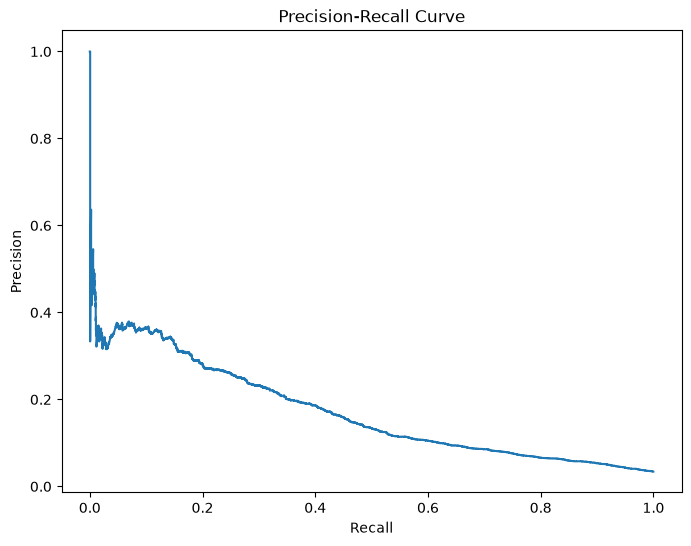

In [72]:
plt.figure(figsize=(8, 6))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.show()

In [73]:
feature_names = preprocessor.get_feature_names_out()

coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": model.coef_[0]
})

coefficients["abs_coefficient"] = coefficients["coefficient"].abs()

In [74]:
coefficients.sort_values(
    "coefficient",
    ascending=False
).head(15)

,feature,coefficient,abs_coefficient
722,categorical__R_emaildomain_protonmail.com,5.264958,5.264958
107,categorical__card3_223.0,4.293128,4.293128
598,categorical__addr2_65.0,4.228918,4.228918
695,categorical__R_emaildomain_earthlink.net,4.064704,4.064704
126,categorical__card5_107.0,3.647243,3.647243
713,categorical__R_emaildomain_mail.com,3.619499,3.619499
448,categorical__addr1_391.0,3.267391,3.267391
192,categorical__card5_191.0,3.064079,3.064079
108,categorical__card3_224.0,2.928169,2.928169
29,categorical__card3_127.0,2.897719,2.897719


In [75]:
coefficients.sort_values(
    "coefficient",
    ascending=True
).head(15)

,feature,coefficient,abs_coefficient
733,categorical__R_emaildomain_verizon.net,-3.446035,3.446035
33,categorical__card3_131.0,-3.425695,3.425695
688,categorical__R_emaildomain_bellsouth.net,-3.380396,3.380396
268,categorical__addr1_148.0,-3.359593,3.359593
146,categorical__card5_131.0,-3.276298,3.276298
48,categorical__card3_149.0,-2.883034,2.883034
687,categorical__R_emaildomain_att.net,-2.837710,2.837710
648,categorical__P_emaildomain_juno.com,-2.781136,2.781136
671,categorical__P_emaildomain_twc.com,-2.749903,2.749903
514,categorical__addr1_486.0,-2.593933,2.593933


## 8. Experiments with C and D features


In [76]:
c_cols = [
    col for col in train.columns
    if col.startswith("C") and col[1:].isdigit()
]

d_cols = [
    col for col in train.columns
    if col.startswith("D") and col[1:].isdigit()
]

In [77]:
print("C features:", len(c_cols))
print(c_cols)

print("\nD features:", len(d_cols))
print(d_cols)

C features: 14
['C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14']

D features: 15
['D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15']


In [78]:
print("\nC missingness:")
print(
    train[c_cols].isna().mean().mul(100).sort_values(ascending=False)
)

print("\nD missingness:")
print(
    train[d_cols].isna().mean().mul(100).sort_values(ascending=False)
)


C missingness:
C1     0.0
C2     0.0
C3     0.0
C4     0.0
C5     0.0
C6     0.0
C7     0.0
C8     0.0
C9     0.0
C10    0.0
C11    0.0
C12    0.0
C13    0.0
C14    0.0
dtype: float64

D missingness:
D7     93.409930
D13    89.509263
D14    89.469469
D12    89.041047
D6     87.606767
D8     87.312290
D9     87.312290
D5     52.467403
D2     47.549192
D11    47.293494
D3     44.514851
D4     28.604667
D15    15.090087
D10    12.873302
D1      0.214888
dtype: float64


In [79]:
train[c_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
C1,590540.0,14.092458,133.569018,0.0,1.0,1.0,3.0,4685.0
C2,590540.0,15.269734,154.668899,0.0,1.0,1.0,3.0,5691.0
C3,590540.0,0.005644,0.150536,0.0,0.0,0.0,0.0,26.0
C4,590540.0,4.092185,68.848459,0.0,0.0,0.0,0.0,2253.0
C5,590540.0,5.571526,25.786976,0.0,0.0,0.0,1.0,349.0
C6,590540.0,9.071082,71.508467,0.0,1.0,1.0,2.0,2253.0
C7,590540.0,2.848478,61.727304,0.0,0.0,0.0,0.0,2255.0
C8,590540.0,5.144574,95.378574,0.0,0.0,0.0,0.0,3331.0
C9,590540.0,4.480240,16.674897,0.0,0.0,1.0,2.0,210.0
C10,590540.0,5.240343,95.581443,0.0,0.0,0.0,0.0,3257.0


In [80]:
train[d_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
D1,589271.0,94.347568,157.660387,0.0,0.000000,3.000000,122.000000,640.000000
D2,309743.0,169.563231,177.315865,0.0,26.000000,97.000000,276.000000,640.000000
D3,327662.0,28.343348,62.384721,0.0,1.000000,8.000000,27.000000,819.000000
D4,421618.0,140.002441,191.096774,-122.0,0.000000,26.000000,253.000000,869.000000
D5,280699.0,42.335965,89.000144,0.0,1.000000,10.000000,32.000000,819.000000
D6,73187.0,69.805717,143.669253,-83.0,0.000000,0.000000,40.000000,873.000000
D7,38917.0,41.638950,99.743264,0.0,0.000000,0.000000,17.000000,843.000000
D8,74926.0,146.058108,231.663840,0.0,0.958333,37.875000,187.958328,1707.791626
D9,74926.0,0.561057,0.316880,0.0,0.208333,0.666666,0.833333,0.958333
D10,514518.0,123.982137,182.615225,0.0,0.000000,15.000000,197.000000,876.000000


In [81]:
numerical_features_v2 = [
    "TransactionAmt"
]

frequency_features_v2 = [
    "card1",
    "card2"
]

onehot_features_v2 = [
    "ProductCD",
    "card3",
    "card4",
    "card5",
    "card6",
    "addr1",
    "addr2",
    "P_emaildomain",
    "R_emaildomain",
    "M1", "M2", "M3", "M4", "M5",
    "M6", "M7", "M8", "M9"
]

cd_features = c_cols + d_cols

numerical_features_v2 += cd_features

In [82]:
print("Numerical:", len(numerical_features_v2))
print("Frequency:", len(frequency_features_v2))
print("Categorical:", len(onehot_features_v2))
print("C/D:", len(cd_features))

Numerical: 30
Frequency: 2
Categorical: 18
C/D: 29


In [83]:
X_train_v2 = train_data[
    numerical_features_v2 +
    frequency_features_v2 +
    onehot_features_v2
].copy()

X_val_v2 = val_data[
    numerical_features_v2 +
    frequency_features_v2 +
    onehot_features_v2
].copy()

In [84]:
y_train_v2 = train_data["isFraud"]
y_val_v2 = val_data["isFraud"]

In [85]:
frequency_maps_v2 = {}

for col in frequency_features_v2:
    frequency_maps_v2[col] = (
        X_train_v2[col]
        .value_counts(normalize=True)
    )

In [86]:
for col in frequency_features_v2:
    X_train_v2[col] = X_train_v2[col].map(
        frequency_maps_v2[col]
    )

    X_val_v2[col] = X_val_v2[col].map(
        frequency_maps_v2[col]
    )

In [87]:
for col in onehot_features_v2:
    X_train_v2[col] = (
        X_train_v2[col]
        .fillna("Missing")
        .astype(str)
    )

    X_val_v2[col] = (
        X_val_v2[col]
        .fillna("Missing")
        .astype(str)
    )

In [88]:
numeric_pipeline_v2 = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

In [89]:
categorical_pipeline_v2 = Pipeline([
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

In [90]:
preprocessor_v2 = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline_v2,
        numerical_features_v2 + frequency_features_v2
    ),
    (
        "categorical",
        categorical_pipeline_v2,
        onehot_features_v2
    )
])

In [91]:
X_train_processed_v2 = preprocessor_v2.fit_transform(
    X_train_v2
)

X_val_processed_v2 = preprocessor_v2.transform(
    X_val_v2
)

In [92]:
print(
    "Train processed shape:",
    X_train_processed_v2.shape
)

print(
    "Validation processed shape:",
    X_val_processed_v2.shape
)

Train processed shape: (413378, 816)
Validation processed shape: (88581, 816)


In [93]:
model_v2 = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model_v2.fit(X_train_processed_v2, y_train_v2)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [94]:
y_val_proba_v2 = model_v2.predict_proba(
    X_val_processed_v2
)[:, 1]

In [95]:
roc_auc_v2 = roc_auc_score(
    y_val_v2,
    y_val_proba_v2
)

pr_auc_v2 = average_precision_score(
    y_val_v2,
    y_val_proba_v2
)

print("ROC-AUC:", roc_auc_v2)
print("PR-AUC:", pr_auc_v2)

ROC-AUC: 0.8280841138559211
PR-AUC: 0.30617981223019325


In [96]:
numerical_features_c = ["TransactionAmt"] + c_cols

frequency_features_c = [
    "card1",
    "card2"
]

onehot_features_c = onehot_features

In [97]:
X_train_c = train_data[
    numerical_features_c +
    frequency_features_c +
    onehot_features_c
].copy()

X_val_c = val_data[
    numerical_features_c +
    frequency_features_c +
    onehot_features_c
].copy()

In [98]:
for col in frequency_features_c:
    X_train_c[col] = X_train_c[col].map(frequency_maps[col])
    X_val_c[col] = X_val_c[col].map(frequency_maps[col])

In [99]:
for col in onehot_features_c:
    X_train_c[col] = X_train_c[col].fillna("Missing").astype(str)
    X_val_c[col] = X_val_c[col].fillna("Missing").astype(str)

In [100]:
preprocessor_c = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numerical_features_c + frequency_features_c
    ),
    (
        "categorical",
        categorical_pipeline,
        onehot_features_c
    )
])

In [101]:
X_train_processed_c = preprocessor_c.fit_transform(X_train_c)
X_val_processed_c = preprocessor_c.transform(X_val_c)

print("Train shape:", X_train_processed_c.shape)
print("Validation shape:", X_val_processed_c.shape)

Train shape: (413378, 786)
Validation shape: (88581, 786)


In [102]:
model_c = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model_c.fit(X_train_processed_c, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [103]:
y_val_proba_c = model_c.predict_proba(
    X_val_processed_c
)[:, 1]

roc_auc_c = roc_auc_score(y_val, y_val_proba_c)
pr_auc_c = average_precision_score(y_val, y_val_proba_c)

print("ROC-AUC:", roc_auc_c)
print("PR-AUC:", pr_auc_c)

ROC-AUC: 0.8121470446840251
PR-AUC: 0.2828898618564505


In [104]:
numerical_features_d = ["TransactionAmt"] + d_cols

frequency_features_d = [
    "card1",
    "card2"
]

onehot_features_d = onehot_features

In [105]:
X_train_d = train_data[
    numerical_features_d +
    frequency_features_d +
    onehot_features_d
].copy()

X_val_d = val_data[
    numerical_features_d +
    frequency_features_d +
    onehot_features_d
].copy()

In [106]:
for col in frequency_features_d:
    X_train_d[col] = X_train_d[col].map(frequency_maps[col])
    X_val_d[col] = X_val_d[col].map(frequency_maps[col])

In [107]:
for col in onehot_features_d:
    X_train_d[col] = X_train_d[col].fillna("Missing").astype(str)
    X_val_d[col] = X_val_d[col].fillna("Missing").astype(str)

In [108]:
preprocessor_d = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numerical_features_d + frequency_features_d
    ),
    (
        "categorical",
        categorical_pipeline,
        onehot_features_d
    )
])

In [109]:
X_train_processed_d = preprocessor_d.fit_transform(X_train_d)
X_val_processed_d = preprocessor_d.transform(X_val_d)

print("Train shape:", X_train_processed_d.shape)
print("Validation shape:", X_val_processed_d.shape)

Train shape: (413378, 802)
Validation shape: (88581, 802)


In [110]:
model_d = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model_d.fit(X_train_processed_d, y_train)

y_val_proba_d = model_d.predict_proba(
    X_val_processed_d
)[:, 1]

roc_auc_d = roc_auc_score(y_val, y_val_proba_d)
pr_auc_d = average_precision_score(y_val, y_val_proba_d)

print("ROC-AUC:", roc_auc_d)
print("PR-AUC:", pr_auc_d)

ROC-AUC: 0.8120321123539628
PR-AUC: 0.21543504080654835


## 9. V-feature exploration and selection


In [111]:
v_cols = [
    col for col in train.columns
    if col.startswith("V") and col[1:].isdigit()
]

print("Number of V features:", len(v_cols))
print(v_cols[:10])
print(v_cols[-10:])

Number of V features: 339
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10']
['V330', 'V331', 'V332', 'V333', 'V334', 'V335', 'V336', 'V337', 'V338', 'V339']


In [112]:
v_stats = pd.DataFrame({
    "missing_pct": train_data[v_cols].isna().mean() * 100,
    "n_unique": train_data[v_cols].nunique(),
    "mean": train_data[v_cols].mean(),
    "std": train_data[v_cols].std()
})

v_stats.sort_values("missing_pct", ascending=False).head(20)

,missing_pct,n_unique,mean,std
V149,84.234768,16,0.779208,0.583050
V150,84.234768,1985,347.400737,917.321972
V146,84.234768,18,0.144023,0.622732
V139,84.234768,34,1.075848,1.342623
V145,84.234768,255,26.769158,71.255327
V144,84.234768,63,4.334249,11.559770
V143,84.234768,55,3.330996,8.679175
V166,84.234768,882,398.262363,1128.847072
V165,84.234768,1151,1702.241974,4363.406669
V164,84.234768,694,307.188852,811.894132


In [113]:
v_stats.sort_values("missing_pct").head(20)

,missing_pct,n_unique,mean,std
V113,0.0,10,1.003646,0.075230
V114,0.0,7,1.008750,0.103373
V115,0.0,7,1.027498,0.174895
V116,0.0,7,1.013823,0.126252
V117,0.0,4,1.000735,0.027375
V118,0.0,4,1.001379,0.037303
V119,0.0,4,1.000927,0.030662
V120,0.0,4,1.001190,0.034966
V121,0.0,4,1.003670,0.060906
V122,0.0,4,1.001747,0.042159


In [114]:
v_stats.sort_values("n_unique").head(20)

,missing_pct,n_unique,mean,std
V107,0.000000,1,1.000000,0.000000
V1,54.616598,2,0.999963,0.006108
V65,15.131671,2,0.999741,0.016103
V41,29.571966,2,0.999420,0.024086
V305,0.002903,2,1.000007,0.002694
V94,16.535955,2,0.142968,0.350040
V88,16.535955,2,0.999357,0.025358
V14,14.808238,2,0.999602,0.019935
V89,16.535955,3,0.000852,0.029963
V68,15.131671,3,0.000499,0.022456


In [115]:
constant_v = v_stats[v_stats["n_unique"] <= 1]

print("Constant V features:")
print(constant_v)
print("\nNumber of constant V features:", len(constant_v))

Constant V features:
      missing_pct  n_unique  mean  std
V107          0.0         1   1.0  0.0

Number of constant V features: 1


In [116]:
low_variation_v = v_stats[v_stats["std"] == 0]

print("Zero-variance V features:")
print(low_variation_v)
print("\nNumber:", len(low_variation_v))

Zero-variance V features:
      missing_pct  n_unique  mean  std
V107          0.0         1   1.0  0.0

Number: 1


In [117]:
v_corr = train_data[v_cols].corrwith(train_data["isFraud"])

v_corr = (
    v_corr
    .abs()
    .sort_values(ascending=False)
)

print(v_corr.head(20))

c:\Users\HP\fraud-detection\venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\HP\fraud-detection\venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


V257    0.370756
V244    0.356585
V242    0.350820
V246    0.347963
V201    0.327629
V200    0.314652
V233    0.306099
V188    0.303172
V189    0.301395
V156    0.285529
V158    0.285295
V232    0.283266
V149    0.282296
V231    0.282250
V217    0.278395
V45     0.277693
V258    0.263296
V44     0.256669
V171    0.251308
V228    0.250680
dtype: float64


In [118]:
v_corr_signed = train_data[v_cols].corrwith(train_data["isFraud"])

v_corr_signed.loc[v_corr.head(20).index]

V257    0.370756
V244    0.356585
V242    0.350820
V246    0.347963
V201    0.327629
V200    0.314652
V233    0.306099
V188    0.303172
V189    0.301395
V156    0.285529
V158    0.285295
V232    0.283266
V149    0.282296
V231    0.282250
V217    0.278395
V45     0.277693
V258    0.263296
V44     0.256669
V171    0.251308
V228    0.250680
dtype: float64

## 10. Logistic Regression with selected V features


In [119]:
top_v_features = v_corr.head(20).index.tolist()

corr_matrix = train_data[top_v_features].corr().abs()

# Keep only the upper triangle
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find feature pairs with correlation >= 0.8
high_corr_pairs = (
    upper.stack()
    .sort_values(ascending=False)
)

high_corr_pairs[high_corr_pairs >= 0.8]

V156  V149    0.973022
V244  V242    0.970805
V201  V200    0.932426
V233  V231    0.924238
V45   V44     0.915719
V156  V158    0.914153
V231  V217    0.910889
V158  V149    0.906501
V257  V246    0.896465
V233  V232    0.888206
V188  V189    0.859241
V233  V217    0.856246
V246  V228    0.831779
V217  V228    0.828563
V257  V44     0.816130
      V231    0.805602
      V217    0.803231
dtype: float64

In [120]:
selected_v = []

for feature in top_v_features:
    if not selected_v:
        selected_v.append(feature)
        continue

    correlations = (
        train_data[selected_v + [feature]]
        .corr()[feature]
        .drop(feature)
        .abs()
    )

    if correlations.max() < 0.8:
        selected_v.append(feature)

print("Original top V features:", len(top_v_features))
print("Selected V features:", len(selected_v))
print("\nSelected features:")
print(selected_v)

Original top V features: 20
Selected V features: 10

Selected features:
['V257', 'V244', 'V201', 'V233', 'V188', 'V156', 'V45', 'V258', 'V171', 'V228']


In [121]:
selected_v_features = selected_v

numerical_features_v_selected = (
    ["TransactionAmt"]
    + c_cols
    + d_cols
    + selected_v_features
)

frequency_features_v_selected = ["card1", "card2"]

onehot_features_v_selected = onehot_features

In [122]:
X_train_v_selected = train_data[
    numerical_features_v_selected
    + frequency_features_v_selected
    + onehot_features_v_selected
].copy()

X_val_v_selected = val_data[
    numerical_features_v_selected
    + frequency_features_v_selected
    + onehot_features_v_selected
].copy()

In [123]:
for col in frequency_features_v_selected:
    X_train_v_selected[col] = X_train_v_selected[col].map(frequency_maps[col])
    X_val_v_selected[col] = X_val_v_selected[col].map(frequency_maps[col])

for col in onehot_features_v_selected:
    X_train_v_selected[col] = (
        X_train_v_selected[col]
        .fillna("Missing")
        .astype(str)
    )

    X_val_v_selected[col] = (
        X_val_v_selected[col]
        .fillna("Missing")
        .astype(str)
    )

In [124]:
preprocessor_v_selected = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numerical_features_v_selected + frequency_features_v_selected
    ),
    (
        "categorical",
        categorical_pipeline,
        onehot_features_v_selected
    )
])

In [125]:
X_train_processed_v_selected = (
    preprocessor_v_selected.fit_transform(X_train_v_selected)
)

X_val_processed_v_selected = (
    preprocessor_v_selected.transform(X_val_v_selected)
)

print("Train shape:", X_train_processed_v_selected.shape)
print("Validation shape:", X_val_processed_v_selected.shape)

Train shape: (413378, 836)
Validation shape: (88581, 836)


In [126]:
model_v_selected = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model_v_selected.fit(
    X_train_processed_v_selected,
    y_train
)

y_val_proba_v_selected = (
    model_v_selected.predict_proba(X_val_processed_v_selected)[:, 1]
)

## 11. Summary of baseline results

Compare validation ROC-AUC and average precision across the baseline experiments. Average precision is referred to as PR-AUC in the experiment outputs.


In [127]:
roc_auc_v_selected = roc_auc_score(
    y_val,
    y_val_proba_v_selected
)

pr_auc_v_selected = average_precision_score(
    y_val,
    y_val_proba_v_selected
)

print("ROC-AUC:", roc_auc_v_selected)
print("PR-AUC:", pr_auc_v_selected)

ROC-AUC: 0.83358384480747
PR-AUC: 0.367239846606461


## Conclusion

The Logistic Regression baseline improves as additional feature groups are introduced. These experiments provide a reference point for the tree-based models developed in `02_xgboost_model.ipynb`. The validation results are used for model comparison; the test set should not be used to choose features or tune thresholds.
